# Retrieval-Augmented Question Answering over the scikit-learn User Guide

**Goal:** answer practical machine learning questions ("which scaler is robust to outliers?") from the scikit-learn User Guide, with every answer citing the page and section it came from.

A RAG system has two halves, and this notebook measures both:

1. **Retrieval**: find the right passages. I compare keyword search (BM25), two kinds of embeddings (LSA and pretrained word vectors) and hybrid combinations, on 50 questions I labeled with the sections that answer them.
2. **Generation**: write an answer from those passages with citations. The pipeline uses Claude when an API key is set and an offline extractive generator otherwise. The examples shown here use the offline generator.

Retrieval quality limits everything downstream: an LLM cannot cite a passage it was never given. So most of the evaluation focuses there.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from docqa.ingest import chunk_docs
from docqa.retrievers import BM25Retriever, LSARetriever, WordVectorRetriever, HybridRetriever, dedupe_by_section
from docqa.evaluate import evaluate, is_relevant
from docqa.generate import ExtractiveGenerator, PROMPT, format_sources
sns.set_theme(style="whitegrid")

## 1. Corpus and chunking

The 45 User Guide pages in reStructuredText (44 contain enough prose to index). Each page is split at its headings, markup is stripped, and each section is cut into 180-word windows with 30 words of overlap. Every chunk keeps its page and section name for citations.

In [2]:
chunks = chunk_docs("../data/docs")
lengths = pd.Series([len(c.text.split()) for c in chunks])
print(f"{len(chunks):,} chunks | {len({c.source for c in chunks})} pages | {len({(c.source, c.section) for c in chunks})} sections")
print(f"words per chunk: median {lengths.median():.0f}, max {lengths.max()}")
print("\nexample:", chunks[300].citation)
print(chunks[300].text[:400], "...")

993 chunks | 44 pages | 513 sections
words per chunk: median 171, max 180

example: ensemble.rst › Interpretation with feature importance
be extended to decision tree ensembles by simply averaging the impurity-based feature importance of each tree (see random_forest_feature_importance for more details). The feature importance scores of a fit gradient boosting model can be accessed via the feature_importances_ property:: array([0.107, 0.105, 0.113, 0.0987, 0.0947, 0.107, 0.0916, 0.0972, 0.0958, 0.0906]) Note that this computation of  ...


## 2. Evaluation set

50 questions written in everyday wording, deliberately not copying the section titles, each labeled with the page and the section(s) that answer it. A retrieval counts as a hit if any relevant section appears in the top k distinct sections.

In [3]:
q = pd.read_csv("../data/eval_questions.csv")
print(len(q), "questions across", q["source"].nunique(), "pages")
q.sample(5, random_state=1)

50 questions across 18 pages


,question,source,relevant_sections
27,Why can impurity-based feature importance be m...,permutation_importance.rst,Relation to impurity-based importance in trees...
35,How do I encode a high-cardinality categorical...,preprocessing.rst,Target Encoder
40,How do I evaluate clustering when I do not hav...,clustering.rst,Silhouette Coefficient;Calinski-Harabasz Index...
38,How do I turn a continuous feature into bins?,preprocessing.rst,K-bins discretization;Discretization
2,Why should I shuffle data before K-fold and wh...,cross_validation.rst,A note on shuffling;K-fold


## 3. Comparing retrievers

In [4]:
bm25, lsa, wv = BM25Retriever(chunks), LSARetriever(chunks), WordVectorRetriever(chunks)
candidates = [bm25, lsa, wv, HybridRetriever([bm25, lsa]), HybridRetriever([bm25, wv]), HybridRetriever([bm25, lsa, wv])]
res = pd.DataFrame({r.name: evaluate(r, q) for r in candidates}).T.round(3)
res

,hit@1,hit@3,hit@5,MRR,ms/query
BM25,0.56,0.76,0.80,0.663,1.196
LSA embeddings,0.56,0.68,0.82,0.650,4.891
Word-vector embeddings,0.28,0.44,0.46,0.362,0.437
Hybrid (BM25 + LSA),0.60,0.76,0.82,0.687,8.619
Hybrid (BM25 + Word-vector),0.48,0.60,0.68,0.556,1.453
Hybrid (BM25 + LSA + Word-vector),0.46,0.68,0.78,0.583,5.750


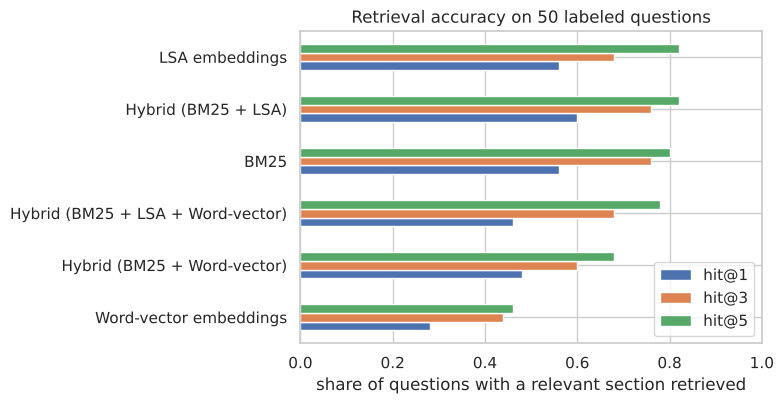

In [5]:
ax = res[["hit@1", "hit@3", "hit@5"]].sort_values("hit@5").plot.barh(figsize=(8, 4.2))
ax.set_xlabel("share of questions with a relevant section retrieved"); ax.set_xlim(0, 1)
ax.set_title("Retrieval accuracy on 50 labeled questions")
plt.tight_layout(); plt.savefig("../images/retrieval_comparison.png", dpi=120); plt.show()

**What this shows**

- BM25 and LSA are close on their own (hit@5 about 0.8), but they succeed on different questions, so fusing them gives the best top-1 accuracy and MRR.
- Averaged pretrained word vectors do poorly here. General-English vectors put "kernel", "forest" and "regression" near their everyday meanings, and averaging a whole chunk blurs it further. Adding them to the hybrid makes it **worse**, a reminder that more retrievers is not automatically better.
- The pipeline therefore uses **BM25 + LSA** by default. Search takes a few milliseconds per question on a laptop.

## 4. Chunk size

In [6]:
rows = []
for words, overlap in [(100, 20), (180, 30), (300, 50)]:
    ch = chunk_docs("../data/docs", max_words=words, overlap=overlap)
    m = evaluate(HybridRetriever([BM25Retriever(ch), LSARetriever(ch)]), q)
    rows.append({"chunk words": words, "chunks": len(ch), **m})
pd.DataFrame(rows).set_index("chunk words").round(3)

,chunks,hit@1,hit@3,hit@5,MRR,ms/query
chunk words,,,,,,
100,1684,0.60,0.72,0.76,0.662,12.271
180,993,0.60,0.76,0.82,0.687,5.253
300,700,0.62,0.74,0.80,0.688,5.061


Small chunks lose context and hurt hit@5; 180 and 300 words perform about the same. I keep 180, since shorter sources leave more room in an LLM prompt.

## 5. Where retrieval fails

In [7]:
hybrid = HybridRetriever([bm25, lsa])
fails = []
for _, row in q.iterrows():
    top = dedupe_by_section(hybrid.search(row["question"], k=60), 5)
    if not any(is_relevant(c, row) for c, _ in top):
        fails.append({"question": row["question"], "expected": f"{row['source']} › {row['relevant_sections'].split(';')[0]}",
                      "retrieved #1": top[0][0].citation})
print(f"{len(fails)} of {len(q)} questions miss in the top 5")
pd.DataFrame(fails)

9 of 50 questions miss in the top 5


,question,expected,retrieved #1
0,Which metric should I use when classes are ver...,model_evaluation.rst › Balanced accuracy score,clustering.rst › Varying the metric
1,How do I write my own scoring function for gri...,model_evaluation.rst › Adapting predefined met...,grid_search.rst › Specifying an objective metric
2,How do I search hyperparameters more cheaply t...,grid_search.rst › Randomized Parameter Optimiz...,grid_search.rst › Parallelism
3,How can I tune parameters of a step inside a p...,grid_search.rst › Composite estimators and par...,compose.rst › Access pipeline steps
4,Can gradient boosting handle missing values wi...,ensemble.rst › Missing values support,impute.rst › Imputation of missing values
5,How do I combine several different models by h...,ensemble.rst › Stacked generalization,ensemble.rst › Voting Regressor
6,How do I fill missing values using the other f...,impute.rst › Multivariate feature imputation,impute.rst › Univariate feature imputation
7,How do I pick the regularization strength for ...,linear_model.rst › Using cross-validation,linear_model.rst › Elastic-Net
8,Why should I scale inputs before training an S...,svm.rst › Tips on Practical Use,neural_networks_supervised.rst › Neural networ...


Most misses are near-misses. The top result is often on the right page or in a closely related section: a question about cheap hyperparameter search lands on grid search "Parallelism" instead of "Randomized Parameter Optimization", and a stacking question lands on "Voting Regressor". The question's wording overlaps more with a neighboring section than with the one that answers it. Two fixes would help: a re-ranker that reads the question and passage together, and neural sentence embeddings that match meaning rather than shared words (see Next steps).

## 6. Answers with citations

The offline generator picks the sentences from the retrieved sources that best match the question and tags each with its source number.

In [8]:
gen = ExtractiveGenerator(embed=lsa.embed)
for question in ["How do I evaluate a model on time-ordered data without training on the future?",
                 "How do I get calibrated probabilities from a classifier whose scores are not reliable?",
                 "Which method isolates anomalies by random splits?"]:
    srcs = [c for c, _ in dedupe_by_section(hybrid.search(question, k=60), 4)]
    ans = gen(question, srcs)
    print("Q:", question); print("A:", ans.text)
    for i, c in enumerate(srcs, 1): print(f"   [{i}] {c.citation}")
    print()

Q: How do I evaluate a model on time-ordered data without training on the future?
A: However, classical cross-validation techniques such as KFold and identically distributed, and would result in unreasonable correlation between training and testing instances (yielding poor estimates of generalization error) on time series data. [1] Therefore, it is very important to evaluate our model for time series data on the "future" observations least like those that are used to train the model. [1] For example, if samples correspond to news articles, and are ordered by their time of publication, then shuffling the data will likely lead to a model that is overfit and an inflated validation score: it will be tested on samples that are artificially similar (close in time) to training samples. [3]
   [1] cross_validation.rst › Cross validation of time series data
   [2] learning_curve.rst › Validation curves: plotting scores to evaluate models
   [3] cross_validation.rst › A note on shuffling
   [4] 

Q: How do I get calibrated probabilities from a classifier whose scores are not reliable?
A: For instance, a well calibrated (binary) classifier should classify the samples such that among the samples to which it gave a predict_proba value close to, say, 0.8, approximately 80% actually belong to the positive class. [1] In the binary case, the probabilities are calibrated using Platt scaling : logistic regression on the SVM's scores, fit by an additional cross-validation on the training data. [2] Each couple is exposed in the `calibrated_classifiers_` attribute, where each entry is a calibrated classifier with a predict_proba method that outputs calibrated probabilities. [4]
   [1] calibration.rst › Probability calibration
   [2] svm.rst › Scores and probabilities
   [3] calibration.rst › Temperature Scaling
   [4] calibration.rst › Usage

Q: Which method isolates anomalies by random splits?
A: One efficient way of performing outlier detection in high-dimensional datasets is to use rand

With an API key, the same sources go to an LLM with this prompt, which restricts it to the sources and requires citations:

In [9]:
print(PROMPT[:420])

You answer questions about the scikit-learn User Guide.
Use only the numbered sources below. Cite sources inline like [1] or [2][3].
If the sources do not contain the answer, say "The documentation excerpts provided do not cover this."
Keep the answer under 120 words.

Sources:
{sources}

Question: {question}
Answer:


## Summary

| | Result |
|---|---|
| Corpus | 44 pages, 513 sections, 993 chunks |
| Best retriever | Hybrid BM25 + LSA with reciprocal rank fusion |
| Top-1 / top-5 hit rate | 60% / 82% on 50 labeled questions |
| Main failure | Near-misses: right page, neighboring section |
| Speed | A few ms per query, no GPU |

**Caveats:** 50 questions is a small test set, and the same set was used to pick the configuration, so the numbers are optimistic. A held-out set is the next thing to add.

**Next steps**

1. Add neural sentence embeddings (for example a MiniLM model) as a third retriever and re-run this evaluation.
2. Add a cross-encoder re-ranker on the top 20 results.
3. Evaluate generated answers for faithfulness: does every cited claim appear in its source?